In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
def load_image(image_path, grayscale=False):
    if grayscale:
        return cv2.imread(image_path, cv2.IMREAD_GRAYSCALE) if image_path else print("Image path is empty.")
    else:
        img = cv2.imread(image_path)
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else print("Image not found or could not be loaded.")


def detect_and_describe_sift(image):
    
    sift = cv2.SIFT_create(
        contrastThreshold=0.04,
        edgeThreshold=10,
        sigma=1.6
    )

    kp, des = sift.detectAndCompute(image, None)
    
    if kp is None or des is None:
        raise ValueError("No keypoints or descriptors found in the image.")

    return kp, des

# A function to find correspondences between two sets of keypoints and descriptors
'''CrossCheck e Lowe's ratio sono mutualmente esclusivi perchè CrossCheck forza ad usare bf.match
e quindi non permette di usare il KNN. Se si vuole usare il KNN, bisogna impostare cross_check=False.
In questo caso, si usa il KNN per trovare i due migliori match per ogni descrittore e poi si applica il test di Lowe's ratio.'''
def kp_matching_bf(des1, des2, norm_type=cv2.NORM_L2, cross_check=True, lowe_ratio=0.8):
    bf = cv2.BFMatcher(norm_type, crossCheck=cross_check)

    if cross_check:
        # Simple matching: only best match with crossCheck
        all_matches = bf.match(des1, des2)
        good_matches = sorted(all_matches, key=lambda x: x.distance)
    else:
        # KNN matching + Lowe's ratio test
        matches = bf.knnMatch(des1, des2, k=2)
        all_matches = [] 
        good_matches = []
        for m, n in matches:
            all_matches.append(m)
            if m.distance < lowe_ratio * n.distance:
                good_matches.append(m)


    return all_matches, good_matches

# Find model object within scene image
def find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches, method=cv2.RANSAC, ransacReprojThreshold=5.0):
    if len(good_matches) < min_match_count:
        return None, None

    src_pts = np.float32([kp_model[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    M, mask = cv2.findHomography(src_pts, dst_pts, method, ransacReprojThreshold)
    
    if M is None:
        raise ValueError("Homography could not be computed.")

    return M, mask

# A function to perform template matching in a region of interest (ROI). To compute the ROI we store the short 
# side of the bounding box, and starting from the ROI, we look 4 times the short side of the bounding on the 
# left and right, and 1 time the short side of the bounding box on the top and bottom. We return the image correspondong to the ROI.
def compute_roi(scene_img, corners, method=cv2.TM_CCOEFF_NORMED):
    # Estrai i punti dai corner nel formato [[[x y]]] → (4, 2)
    corners = corners.reshape(-1, 2)

    # Calcola bounding box axis-aligned (x_min, y_min) → (x_max, y_max)
    x_min = np.min(corners[:, 0])
    x_max = np.max(corners[:, 0])
    y_min = np.min(corners[:, 1])
    y_max = np.max(corners[:, 1])

    width = x_max - x_min
    height = y_max - y_min

    short_side = min(width, height)

    # ROI esteso attorno al bounding box
    roi_x_min = max(0, int(x_min - 3 * short_side))
    roi_x_max = min(scene_img.shape[1], int(x_max + 3 * short_side))
    roi_y_min = max(0, int(y_min - 1 * short_side))
    roi_y_max = min(scene_img.shape[0], int(y_max + 1 * short_side))

    # Estrai ROI
    roi_scene = scene_img[roi_y_min:roi_y_max, roi_x_min:roi_x_max]

    return roi_scene

def perform_template_matching(scene_img, template_img, method=cv2.TM_CCOEFF_NORMED, threshold=0.60):

    # Se le immagini sono a colori, convertile in scala di grigi
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_gray = template_img.copy()

    # Esegui il template matching
    result = cv2.matchTemplate(scene_gray, template_gray, method)
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

    # Scegli il metodo di selezione del miglior match
    if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
        match_val = min_val
        top_left = min_loc
        matched = match_val <= threshold
    else:
        match_val = max_val
        top_left = max_loc
        print(f"Match value: {match_val}, Threshold: {threshold}")
        matched = match_val >= threshold

    # Calcola coordinate opposte (larghezza/altezza del template)
    h, w = template_gray.shape[:2]
    bottom_right = (top_left[0] + w, top_left[1] + h)

    # Compute the 4 corners in the format [[[x1, y1]], [[x2, y2]], [[x3, y3]], [[x4, y4]]]
    corners = np.array([[list(top_left)],[list((top_left[0], bottom_right[1]))], [list(bottom_right)], [list((bottom_right[0], top_left[1]))]])

    if matched:
        return corners, match_val
    else:
        return None, match_val  # Nessun match sopra la soglia
    

def perform_template_matching_rot(scene_img, template_img, method=cv2.TM_CCOEFF_NORMED, threshold=0.60, angles=range(-6, 7, 2)):

    # Se le immagini sono a colori, convertile in scala di grigi
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_gray = template_img.copy()

    best_match_val = -np.inf
    top_left_best = None

    (h0, w0) = template_img.shape[:2]

    for angle in angles:
        # Ruota l'immagine del template
        rot_mat = cv2.getRotationMatrix2D((w0/2, h0/2), angle, 1.0)
        template_rot = cv2.warpAffine(template_gray, rot_mat, (w0, h0), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

        # Esegui il template matching
        result = cv2.matchTemplate(scene_gray, template_rot, method)
        min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

        # Scegli il metodo di selezione del miglior match
        if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
            match_val = min_val
            top_left = min_loc
        else:
            match_val = max_val
            top_left = max_loc
            
            
        # Aggiorna il miglior match se necessario
        if match_val > best_match_val:
            best_match_val = match_val
            top_left_best = top_left

    print(f"Match value: {best_match_val}, Threshold: {threshold}")

    matched = best_match_val >= threshold


    if matched:
        # Calcola coordinate opposte (larghezza/altezza del template)
        h, w = template_gray.shape[:2]
        bottom_right_best = (top_left_best[0] + w, top_left_best[1] + h)

        # Compute the 4 corners in the format [[[x1, y1]], [[x2, y2]], [[x3, y3]], [[x4, y4]]]
        corners = np.array([[list(top_left_best)],[list((top_left_best[0], bottom_right_best[1]))], [list(bottom_right_best)], [list((bottom_right_best[0], top_left_best[1]))]])

        return corners, best_match_val
    else:
        return None, best_match_val  # Nessun match sopra la soglia
    

def perform_template_matching_rot_scale(scene_img, template_img, method=cv2.TM_SQDIFF_NORMED, threshold=0.60, angles=range(-6, 7, 2), scales=np.linspace(0.8, 1.2, 5)):

    # Se le immagini sono a colori, convertile in scala di grigi
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_orig_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_orig_gray = template_img.copy()

    best_match_val = -np.inf
    top_left_best = None
    best_w = None
    best_h = None

    for scale in scales:
        # Ridimensiona il template
        scaled_template = cv2.resize(template_orig_gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        h0, w0 = scaled_template.shape[:2]

        for angle in angles:
            # Ruota il template scalato
            rot_mat = cv2.getRotationMatrix2D((w0 / 2, h0 / 2), angle, 1.0)
            rotated_template = cv2.warpAffine(scaled_template, rot_mat, (w0, h0), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

            # Salta se il template diventa più grande della scena
            if rotated_template.shape[0] > scene_gray.shape[0] or rotated_template.shape[1] > scene_gray.shape[1]:
                continue

            # Esegui il template matching
            result = cv2.matchTemplate(scene_gray, rotated_template, method)
            min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

            if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
                match_val = -min_val  # Per coerenza, invertiamo SQDIFF
                top_left = min_loc
            else:
                match_val = max_val
                top_left = max_loc

            if match_val < best_match_val:
                best_match_val = match_val
                top_left_best = top_left
                best_w = w0
                best_h = h0

    print(f"Match value: {best_match_val}, Threshold: {threshold}")
    matched = best_match_val <= threshold

    if matched and top_left_best:
        bottom_right_best = (top_left_best[0] + best_w, top_left_best[1] + best_h)

        corners = np.array([
            [list(top_left_best)],
            [list((top_left_best[0], bottom_right_best[1]))],
            [list(bottom_right_best)],
            [list((bottom_right_best[0], top_left_best[1]))]
        ])

        return corners, best_match_val
    else:
        return None, best_match_val  # Nessun match sopra la soglia


def extract_template_from_corners(image, corners):

    # Assicura che corners sia nella forma corretta
    corners = corners.reshape(-1, 2).astype(np.int32)

    # Crea una maschera nera
    mask = np.zeros(image.shape[:2], dtype=np.uint8)

    # Disegna il poligono bianco sulla maschera
    cv2.fillPoly(mask, [corners], 255)

    # Applica la maschera all'immagine originale
    masked = cv2.bitwise_and(image, image, mask=mask)

    # Bounding rect per ritagliare solo la regione di interesse (senza bordi neri intorno)
    x, y, w, h = cv2.boundingRect(corners)
    cropped_region = masked[y:y+h, x:x+w]

    return cropped_region

def show_keypoints(image, keypoints):
    img_with_keypoints = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.figure(figsize=(10, 10))
    plt.imshow(img_with_keypoints)
    plt.axis('off')
    plt.show()

def show_correspondences(image1, image2, kp1, kp2, matches):
    img_matches = cv2.drawMatches(image1, kp1, image2, kp2, matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(15, 10))
    plt.imshow(img_matches)
    plt.axis('off')
    plt.show()

# Function to draw the bounding box around the detected model in the scene
def draw_bounding_box(img_scene, img_model, M):
    # Corners of the model image
    h, w = img_model.shape[:2]
    pts = np.float32([[0,0], [0,h-1], [w-1,h-1], [w-1,0]]).reshape(-1, 1, 2)

    # Project the corners into the scene image
    dst = cv2.perspectiveTransform(pts, M)

    # Draw the bounding box
    img_scene_with_box = cv2.polylines(img_scene, [np.int32(dst)], True, (255, 0, 0), 3, cv2.LINE_AA)

    return np.int32(dst), img_scene_with_box

def draw_matched_rectangle(image,corners):

    image_with_rectangle = image.copy()
    cv2.polylines(image_with_rectangle, [corners], True, (0, 255, 0), 2)
    return image_with_rectangle

# A function to remove the detected object from the scene image
def remove_object_from_scene(img_scene, corners):
    # Create a mask for the detected object
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [corners], (255))

    # Invert the mask to keep the background
    mask_inv = cv2.bitwise_not(mask)

    # Remove the object from the scene image
    img_scene_no_object = cv2.bitwise_and(img_scene, img_scene, mask=mask_inv)

    return img_scene_no_object


In [16]:

def main(model_path, scene_path, 
         grayscale=False,
         matching_threshold=0.60, 
         min_match_pct=0.1,
         cross_check=False, 
         lowe_ratio=0.8, 
         method=cv2.RANSAC, 
         ransacReprojThreshold=5.0, 
         similarity_measure=cv2.TM_CCOEFF_NORMED):

    detections = 0

    model_img = load_image(model_path, grayscale=grayscale)
    scene_img = load_image(scene_path, grayscale=grayscale)

    scene = scene_img.copy()

    # Detect keypoints and descriptors
    kp_model, des_model = detect_and_describe_sift(model_img)
    kp_scene, des_scene = detect_and_describe_sift(scene_img)

    # Match keypoints
    all_matches, good_matches = kp_matching_bf(des_model, des_scene, norm_type=cv2.NORM_L2, cross_check=cross_check, lowe_ratio=lowe_ratio)

    # Find homography
    min_match_count = int(min_match_pct * len(kp_model))
    M, mask = find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches)
    if M is None:
        print("Homography could not be computed. No instances detected.")
        return
    else:
        print(f"Homography computed successfully")
    
    detections += 1

    # Draw bounding box around the detected model in the scene
    corners, img_scene_with_box = draw_bounding_box(scene, model_img, M)

    # Compute ROI from the corners
    # roi_scene = compute_roi(scene_img, corners)

    # Extract the template to permit template matching
    template = extract_template_from_corners(scene, corners)

    while True:
        # Mask the object detected
        scene_img = remove_object_from_scene(scene_img, corners)

        # Perform template matching in the ROI
        corners, match_val = perform_template_matching_rot_scale(scene_img, template, method=similarity_measure, threshold=matching_threshold)

        if corners is None:
            print(f"No match found during template matching on instance {detections+1}. Matching value: {match_val}/{matching_threshold}.")
            break

        detections += 1

        scene = draw_matched_rectangle(scene, corners)
        
    print(f"Total instances detected: {detections}")
    if detections > 0:
        plt.imshow(scene)
        plt.show()




Homography computed successfully
Match value: 0.6439980268478394, Threshold: 0.55
Match value: 0.5825332403182983, Threshold: 0.55
Match value: 0.6049334406852722, Threshold: 0.55
Match value: 0.578571081161499, Threshold: 0.55
Match value: 0.6267852187156677, Threshold: 0.55
Match value: 0.5719583034515381, Threshold: 0.55
Match value: 0.5928014516830444, Threshold: 0.55
Match value: 0.5360894203186035, Threshold: 0.55
No match found during template matching on instance 9. Matching value: 0.5360894203186035/0.55.
Total instances detected: 8


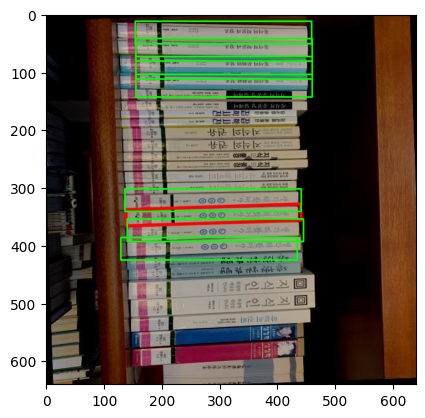

In [ ]:
grayscale = False
crosscheck = False
lowe_ratio = 0.75
matching_threshold = 0.7
min_match_pct = 0.1
scene_path = f'./dataset/scenes/scene_9.jpg'



model_path = f'./dataset/models/model_19.png'

main(model_path, scene_path, 
    grayscale=grayscale, 
    matching_threshold=matching_threshold, 
    min_match_pct=min_match_pct,
    cross_check=crosscheck, 
    lowe_ratio=lowe_ratio, 
    method=cv2.RANSAC, 
    ransacReprojThreshold=5.0, 
    similarity_measure=cv2.TM_CCOEFF_NORMED)

--------------------------------- Processing scene 0 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be comput

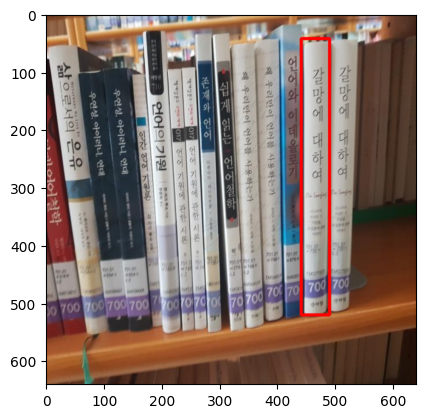

-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 2 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be com

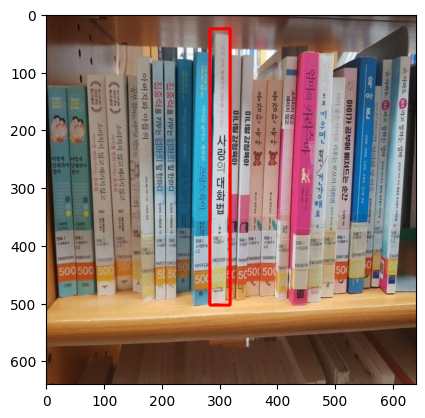

-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 3 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be co

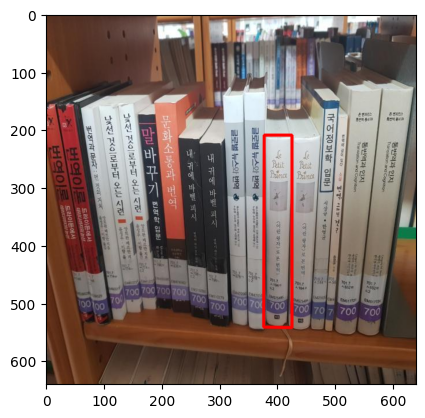

-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 4 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be c

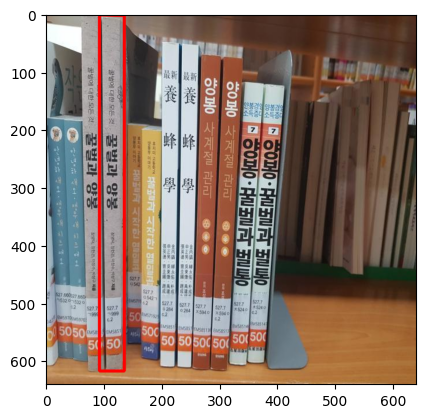

-------- Processing model 15 --------
Homography computed successfully
Match value: 0.6240065097808838, Threshold: 0.3
No match found during template matching on instance 2. Matching value: 0.6240065097808838/0.3.
Total instances detected: 1


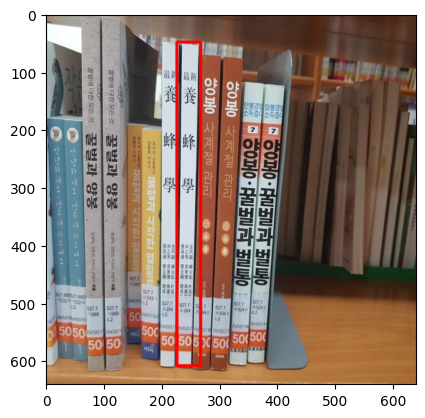

-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 5 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be 

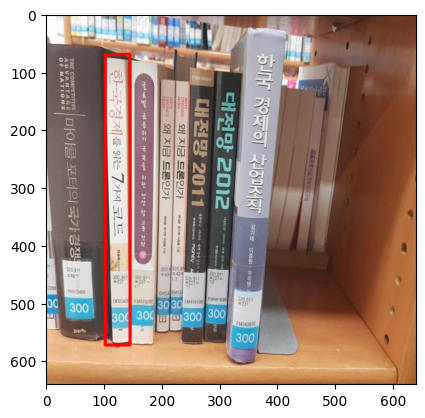

-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 6 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not b

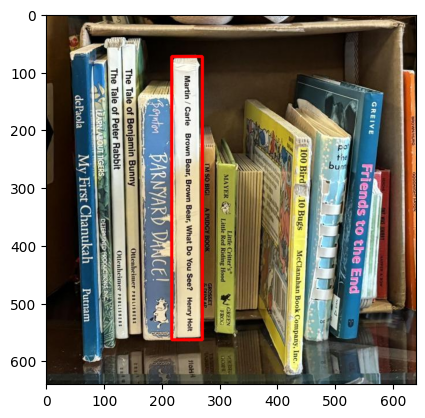

--------------------------------- Processing scene 7 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.

KeyboardInterrupt: 

In [ ]:
grayscale = False
crosscheck = False
lowe_ratio = 0.75
matching_threshold = 0.3
min_match_pct = 0.1

for i in range(0, 29):
     print(f"--------------------------------- Processing scene {i} ---------------------------------")
     scene_path = f'./dataset/scenes/scene_{i}.jpg'
     for j in range(0, 22):
          print(f"-------- Processing model {j} --------")

          model_path = f'./dataset/models/model_{j}.png'
          
          main(model_path, scene_path, 
               grayscale=grayscale, 
               matching_threshold=matching_threshold, 
               min_match_pct=min_match_pct,
               cross_check=crosscheck, 
               lowe_ratio=lowe_ratio, 
               method=cv2.RANSAC, 
               ransacReprojThreshold=5.0, 
               similarity_measure=cv2.TM_CCOEFF_NORMED)

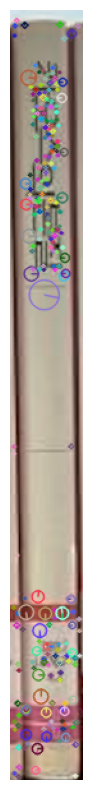

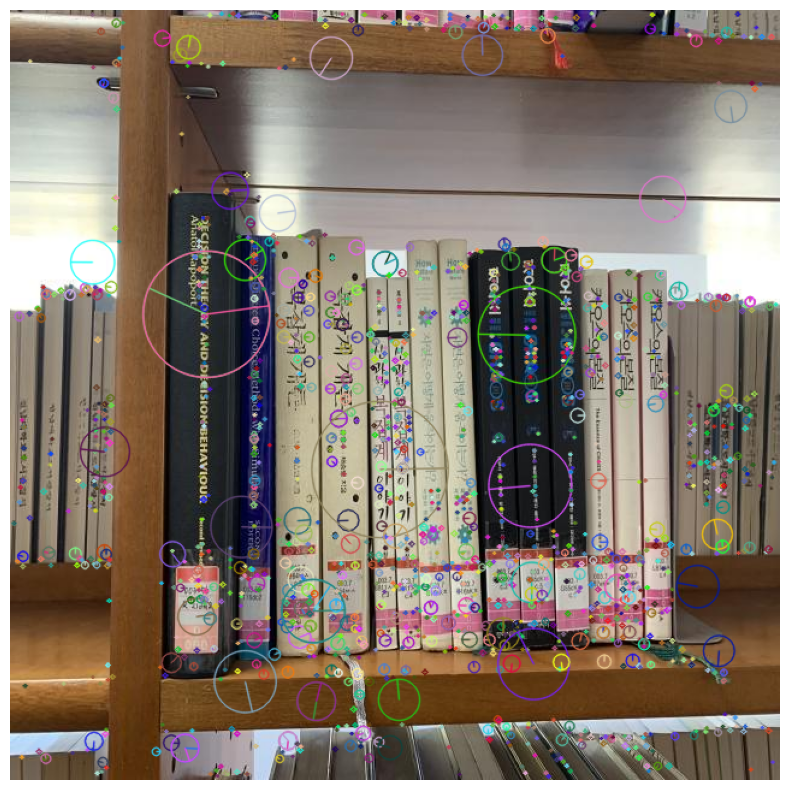

In [121]:
grayscale = False
model_path = './dataset/models/model_12.png'
scene_path = './dataset/scenes/scene_17.jpg'


model_img = load_image(model_path, grayscale=grayscale)
scene_img = load_image(scene_path, grayscale=grayscale)

kp_model, des_model = detect_and_describe_sift(model_img)
kp_scene, des_scene = detect_and_describe_sift(scene_img)

show_keypoints(model_img, kp_model)
show_keypoints(scene_img, kp_scene)


(< cv2.DMatch 0x11e1cba10>, < cv2.DMatch 0x11e1cb0d0>, < cv2.DMatch 0x11e2a4330>, < cv2.DMatch 0x11e2a42d0>, < cv2.DMatch 0x11e2a41d0>, < cv2.DMatch 0x11e2a4230>, < cv2.DMatch 0x11e2a41f0>, < cv2.DMatch 0x11e2a4490>, < cv2.DMatch 0x11e2a4350>, < cv2.DMatch 0x11e2a42f0>, < cv2.DMatch 0x11e2a4450>, < cv2.DMatch 0x11e2a4210>, < cv2.DMatch 0x11e2a41b0>, < cv2.DMatch 0x11e2a4410>, < cv2.DMatch 0x11e2a43d0>, < cv2.DMatch 0x11e2a4430>, < cv2.DMatch 0x11e2a4290>, < cv2.DMatch 0x11e2a4310>, < cv2.DMatch 0x11e2a4530>, < cv2.DMatch 0x11e2a4510>, < cv2.DMatch 0x11e2a44d0>, < cv2.DMatch 0x11e2a4570>, < cv2.DMatch 0x11e2a44b0>, < cv2.DMatch 0x11e2a45b0>, < cv2.DMatch 0x11e2a4550>, < cv2.DMatch 0x11e2a4590>, < cv2.DMatch 0x11e2a45d0>, < cv2.DMatch 0x11e2a45f0>, < cv2.DMatch 0x11e2a4610>, < cv2.DMatch 0x11e2a4630>, < cv2.DMatch 0x11e2a4650>, < cv2.DMatch 0x11e2a4670>, < cv2.DMatch 0x11e2a4690>, < cv2.DMatch 0x11e2a46b0>, < cv2.DMatch 0x11e2a46d0>, < cv2.DMatch 0x11e2a46f0>, < cv2.DMatch 0x11e2a4710>, 

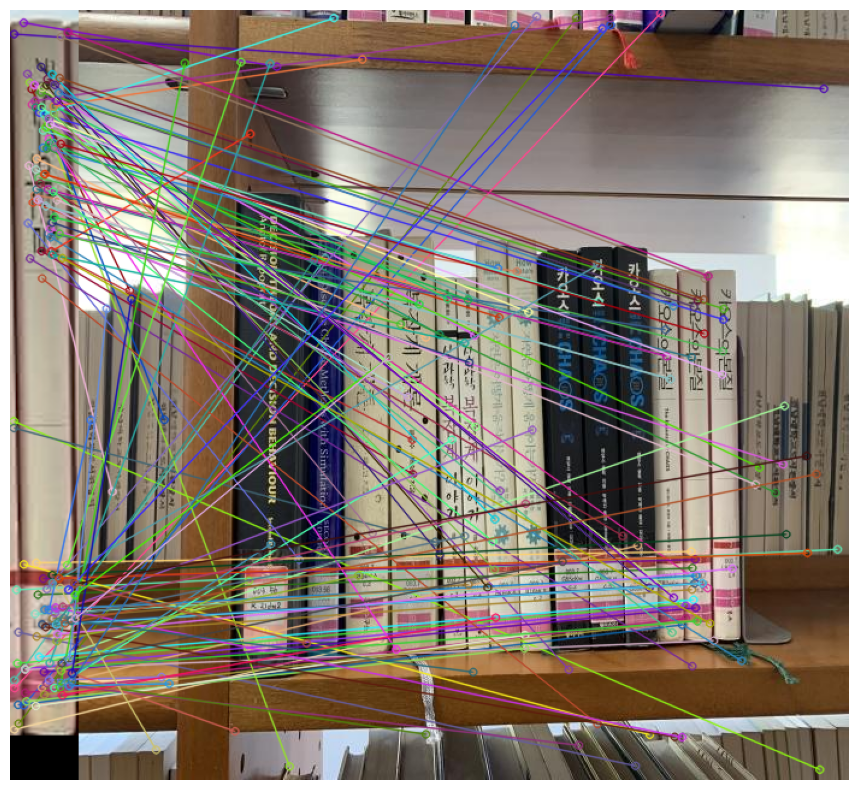

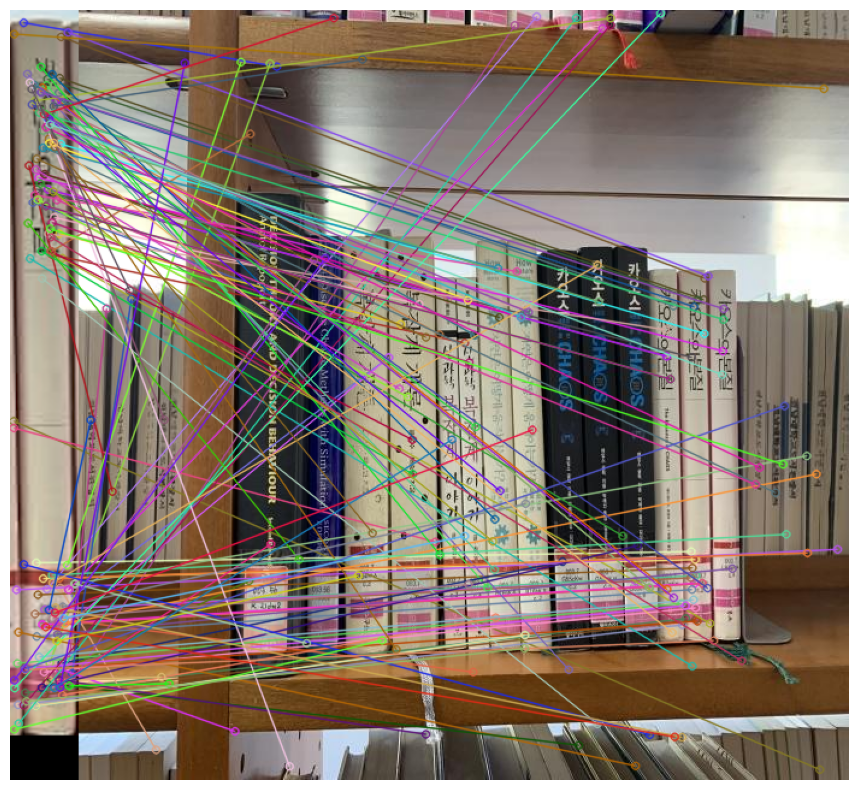

In [122]:
# Find correspondences
all_matches, good_matches = kp_matching_bf(des_model, des_scene, norm_type=cv2.NORM_L2, cross_check=True, lowe_ratio=0.7)
print(all_matches)
show_correspondences(model_img, scene_img, kp_model, kp_scene, all_matches)
show_correspondences(model_img, scene_img, kp_model, kp_scene, good_matches)

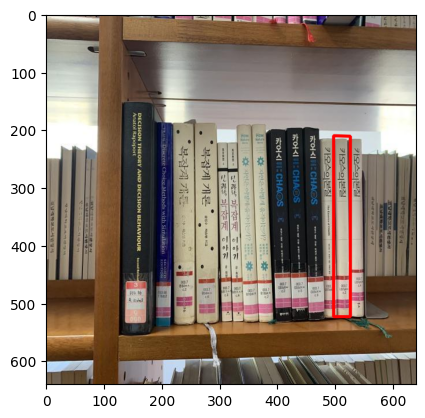

In [123]:
# compute homography
min_match_count = 10
M, mask = find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches, method=cv2.RANSAC, ransacReprojThreshold=5.0)
corners, img_scene_with_box = draw_bounding_box(scene_img, model_img, M)
plt.imshow(img_scene_with_box)

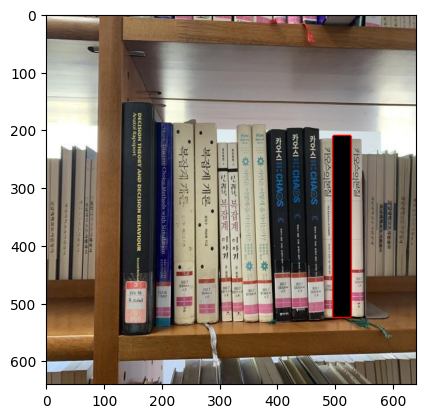

In [111]:
# Remove the detected object from the scene
img_scene_no_object = remove_object_from_scene(scene_img, corners)
plt.imshow(img_scene_no_object)

[[[497 211]]

 [[497 523]]

 [[526 523]]

 [[526 211]]]


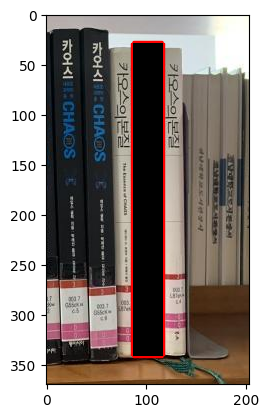

In [112]:
print(corners)
roi_scene = compute_roi(img_scene_no_object, corners)
plt.imshow(roi_scene)

In [115]:
cropped_region = extract_region_from_corners(scene_img, corners)
top_left, bottom_right, match_val = perform_template_matching(roi_scene, cropped_region)
print(top_left, bottom_right, match_val)

(112, 57) (142, 370) 0.6886316537857056


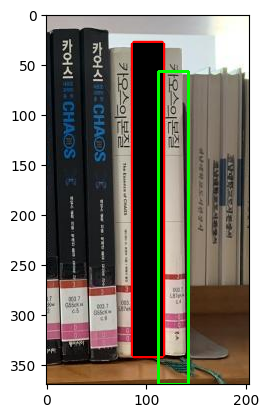

In [116]:
# Draw rectangle around the matched region
def draw_matched_rectangle(image, top_left, bottom_right):

    image_with_rectangle = image.copy()
    cv2.rectangle(image_with_rectangle, top_left, bottom_right, (0, 255, 0), 2)
    return image_with_rectangle

img_with_rectangle = draw_matched_rectangle(roi_scene, top_left, bottom_right)
plt.imshow(img_with_rectangle)

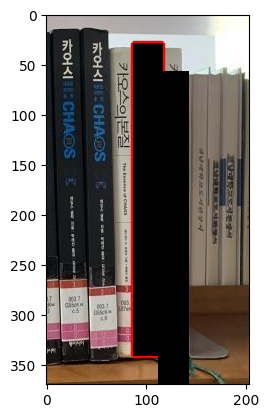

In [117]:
corners = np.array([
    top_left,
    (top_left[0], bottom_right[1]),
    bottom_right,
    (bottom_right[0], top_left[1])
], dtype=np.int32)
roi_scene = remove_object_from_scene(roi_scene, corners)
plt.imshow(roi_scene)

In [118]:
print([[list(top_left)],[list((top_left[0], bottom_right[1]))], [list(bottom_right)], [list((bottom_right[0], top_left[1]))]])

top_left, bottom_right, match_val = perform_template_matching(roi_scene, cropped_region)
print(top_left, bottom_right, match_val)

[[[112, 57]], [[112, 370]], [[142, 370]], [[142, 57]]]
(61, 28) (91, 341) 0.6232571601867676


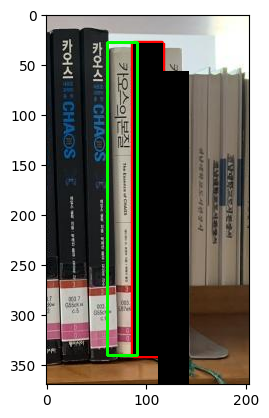

In [ ]:
# Draw rectangle around the matched region


img_with_rectangle = draw_matched_rectangle(roi_scene, top_left, bottom_right)
plt.imshow(img_with_rectangle)